# Diagnóstico inicial reproducible (fase 1)

Este cuaderno descarga datos **pseudonimizados** desde GitHub y genera automáticamente las tablas y gráficos del diagnóstico inicial. Para ejecutar: configurar `PROPIETARIO_GITHUB` y seleccionar **Entorno de ejecución → Ejecutar todo**. No requiere Google Drive.

**Publicación condicionada:** los datos mantienen fechas y cantidades originales; no publicar sin revisar el alcance de la autorización y el riesgo de reidentificación.


In [68]:
# Modo público: cargar automáticamente los CSV del repositorio GitHub.
# Configura PROPIETARIO_GITHUB con el propietario REAL de tu repositorio.
import pandas as pd
import matplotlib.pyplot as plt

PROPIETARIO_GITHUB = "adrianamarcelayavi-cmyk"  # modificar una sola vez antes de publicar
REPOSITORIO = "tesis-bi-cbn"
RAMA = "main"
if PROPIETARIO_GITHUB == "REEMPLAZAR_USUARIO":
    raise ValueError("Escribe el nombre real del propietario de GitHub en PROPIETARIO_GITHUB")
base_url = f"https://raw.githubusercontent.com/{PROPIETARIO_GITHUB}/{REPOSITORIO}/refs/heads/{RAMA}/data/sample"
url_datos = base_url + "/datos_diagnostico_pseudonimizados.csv"
url_catalogo = base_url + "/catalogo_pseudonimizado.csv"
df = pd.read_csv(url_datos, dtype=str, encoding="utf-8-sig")
maestro = pd.read_csv(url_catalogo, dtype=str, encoding="utf-8-sig")
print("DATOS HISTÓRICOS:", df.shape)
print("CATÁLOGO:", maestro.shape)


DATOS HISTÓRICOS: (501, 12)
CATÁLOGO: (70, 3)


VER LOS NOMBRES DE LAS COLUMNAS

In [69]:

# Mostrar los nombres de todas las columnas
df.columns.tolist()


['MOTIVO',
 'FECHA DE REVISIÓN',
 'PUNTO DE VENTA',
 'PRODUCTO',
 'CANTIDAD',
 'FECHA',
 'NOMBRE ESTÁNDAR',
 'CÓDIGO DE BARRA',
 'CÓDIGO DE PRODUCTO',
 'ESTA EN EL NO CANJEO',
 'DENTRO LOS MESES',
 'CUMPLE CAMBIO']

ELIMINAR COLUMNAS INNECESARIAS

In [70]:

# Crear una copia para no modificar la base original
df_diagnostico = df.copy()

# Eliminar columnas innecesarias
df_diagnostico = df_diagnostico.drop(columns=[
    'ESTA EN EL NO CANJEO',
    'DENTRO LOS MESES',
    'CUMPLE CAMBIO'
])

# Mostrar las columnas restantes
df_diagnostico.columns.tolist()


['MOTIVO',
 'FECHA DE REVISIÓN',
 'PUNTO DE VENTA',
 'PRODUCTO',
 'CANTIDAD',
 'FECHA',
 'NOMBRE ESTÁNDAR',
 'CÓDIGO DE BARRA',
 'CÓDIGO DE PRODUCTO']

TIPOS DE VARIABLES

In [71]:
# Verificar los tipos de datos
df_diagnostico.dtypes



,0
MOTIVO,object
FECHA DE REVISIÓN,object
PUNTO DE VENTA,object
PRODUCTO,object
CANTIDAD,object
FECHA,object
NOMBRE ESTÁNDAR,object
CÓDIGO DE BARRA,object
CÓDIGO DE PRODUCTO,object


CONVERTIR MOTIVO A CATEGORÍA

In [72]:
# Verificar los valores de MOTIVO
df_diagnostico['MOTIVO'].value_counts(dropna=False)


,count
MOTIVO,
PINCHADO,271
VENCIDO,230


In [73]:

# Convertir MOTIVO a variable categórica
df_diagnostico['MOTIVO'] = (
    df_diagnostico['MOTIVO']
    .astype('category')
)

# Verificar el nuevo tipo de dato
df_diagnostico['MOTIVO'].dtype


CategoricalDtype(categories=['PINCHADO', 'VENCIDO'], ordered=False, categories_dtype=object)

FORMATO DE LAS FECHAS

In [74]:
# Observar los primeros 10 valores de FECHA DE REVISIÓN
df_diagnostico['FECHA DE REVISIÓN'].head(10)


,FECHA DE REVISIÓN
0,3/30/2026
1,3/30/2026
2,3/30/2026
3,3/30/2026
4,3/30/2026
5,3/30/2026
6,3/30/2026
7,3/30/2026
8,3/30/2026
9,3/30/2026


In [75]:
# Convertir la columna a tipo fecha
df_diagnostico['FECHA DE REVISIÓN'] = pd.to_datetime(
    df_diagnostico['FECHA DE REVISIÓN'],
    format='%m/%d/%Y',
    errors='coerce'
)


# Comprobar el tipo de dato
print(df_diagnostico['FECHA DE REVISIÓN'].dtype)

# Contar fechas vacías o inválidas
print("Fechas faltantes o inválidas:",
      df_diagnostico['FECHA DE REVISIÓN'].isna().sum())



datetime64[ns]
Fechas faltantes o inválidas: 2


PARA PUNTO DE VENTA

In [76]:
# Contar registros por punto de venta
df_diagnostico['PUNTO DE VENTA'].value_counts(dropna=False)



,count
PUNTO DE VENTA,
SUCURSAL_001,122
SUCURSAL_006,95
SUCURSAL_002,69
SUCURSAL_003,64
SUCURSAL_004,60
SUCURSAL_005,45
SUCURSAL_007,34
NaN,12


In [77]:
# Convertir PUNTO DE VENTA a variable categórica
df_diagnostico['PUNTO DE VENTA'] = (
    df_diagnostico['PUNTO DE VENTA']
    .astype('category')
)

# Verificar el tipo de variable
df_diagnostico['PUNTO DE VENTA'].dtype


CategoricalDtype(categories=['SUCURSAL_001', 'SUCURSAL_002', 'SUCURSAL_003',
                  'SUCURSAL_004', 'SUCURSAL_005', 'SUCURSAL_006',
                  'SUCURSAL_007'],
, ordered=False, categories_dtype=object)

CANTIDAD

In [78]:
# Observar los primeros 10 valores de CANTIDAD
df_diagnostico['CANTIDAD'].head(10)


,CANTIDAD
0,3
1,2
2,1
3,2
4,1
5,1
6,1
7,1
8,1
9,1


In [79]:
# Convertir CANTIDAD a tipo numérico
df_diagnostico['CANTIDAD'] = pd.to_numeric(
    df_diagnostico['CANTIDAD'],
    errors='coerce'
).astype('Int64')


In [80]:
# Verificar tipo de dato
print(df_diagnostico['CANTIDAD'].dtype)

# Contar cantidades faltantes
print("Cantidades faltantes:",
      df_diagnostico['CANTIDAD'].isna().sum())


Int64
Cantidades faltantes: 16


FECHA

In [81]:
# Observar los primeros 15 valores de FECHA
df_diagnostico['FECHA'].head(15)


,FECHA
0,NaN
1,NaN
2,NaN
3,NaN
4,NaN
5,NaN
6,NaN
7,NaN
8,NaN
9,NaN


In [82]:
# Convertir FECHA a tipo fecha
df_diagnostico['FECHA'] = pd.to_datetime(
    df_diagnostico['FECHA'],
    format='%m/%d/%Y',
    errors='coerce'
)


In [83]:
# Verificar el tipo de dato
print(df_diagnostico['FECHA'].dtype)

# Contar fechas faltantes
print("Fechas faltantes:",
      df_diagnostico['FECHA'].isna().sum())


datetime64[ns]
Fechas faltantes: 273


NOMBRE ESTÁNDAR

In [84]:
# Convertir NOMBRE ESTÁNDAR a texto
df_diagnostico['NOMBRE ESTÁNDAR'] = (
    df_diagnostico['NOMBRE ESTÁNDAR']
    .astype('string')
    .str.strip()
    .str.upper()
)


In [85]:
# Verificar el tipo de dato
print(df_diagnostico['NOMBRE ESTÁNDAR'].dtype)

# Mostrar los primeros 10 valores
df_diagnostico['NOMBRE ESTÁNDAR'].head(10)


string


,NOMBRE ESTÁNDAR
0,ARTICULO_244
1,ARTICULO_244
2,ARTICULO_138
3,ARTICULO_244
4,ARTICULO_138
5,ARTICULO_239
6,ARTICULO_181
7,ARTICULO_156
8,ARTICULO_007
9,ARTICULO_211


CÓDIGOS DE BARRAS Y DE PRODUCTO

In [86]:
# Convertir CÓDIGO DE BARRA a texto
df_diagnostico['CÓDIGO DE BARRA'] = (
    df_diagnostico['CÓDIGO DE BARRA']
    .astype('string')
    .str.strip()
)


In [87]:
# Convertir CÓDIGO DE PRODUCTO a texto
df_diagnostico['CÓDIGO DE PRODUCTO'] = (
    df_diagnostico['CÓDIGO DE PRODUCTO']
    .astype('string')
    .str.strip()
)


In [88]:
# Verificar los tipos de todas las variables
df_diagnostico.dtypes


,0
MOTIVO,category
FECHA DE REVISIÓN,datetime64[ns]
PUNTO DE VENTA,category
PRODUCTO,object
CANTIDAD,Int64
FECHA,datetime64[ns]
NOMBRE ESTÁNDAR,string[python]
CÓDIGO DE BARRA,string[python]
CÓDIGO DE PRODUCTO,string[python]


ESTADÍSTICAS GENERALES DE LA BASE DE DATOS

In [89]:
# Estadísticas generales de la base
print("Total de registros:", len(df_diagnostico))
print("Total de variables:", df_diagnostico.shape[1])

print("Número de sucursales:",
      df_diagnostico['PUNTO DE VENTA'].nunique())

print("Nombres estándar diferentes:",
      df_diagnostico['NOMBRE ESTÁNDAR'].nunique())


Total de registros: 501
Total de variables: 9
Número de sucursales: 7
Nombres estándar diferentes: 56


DISTRIBUCIÓN DE REGISTROS SEGÚN MOTIVO

In [90]:
# Contar registros según el motivo
df_diagnostico['MOTIVO'].value_counts()


,count
MOTIVO,
PINCHADO,271
VENCIDO,230


In [91]:
# Crear tabla de estadísticas generales
resumen_general = pd.DataFrame({
    'INDICADOR': [
        'Total de registros',
        'Número de variables',
        'Sucursales',
        'Nombres estándar diferentes',
        'Registros vencidos',
        'Registros pinchados'
    ],
    'VALOR': [
        len(df_diagnostico),
        df_diagnostico.shape[1],
        df_diagnostico['PUNTO DE VENTA'].nunique(),
        df_diagnostico['NOMBRE ESTÁNDAR'].nunique(),
        (df_diagnostico['MOTIVO'] == 'VENCIDO').sum(),
        (df_diagnostico['MOTIVO'] == 'PINCHADO').sum()
    ]
})

display(resumen_general)


,INDICADOR,VALOR
0,Total de registros,501
1,Número de variables,9
2,Sucursales,7
3,Nombres estándar diferentes,56
4,Registros vencidos,230
5,Registros pinchados,271


DEFINIR COLUMNAS OBLIGATORIAS

In [92]:
# Definir las columnas obligatorias
columnas_obligatorias = [
    'MOTIVO',
    'FECHA DE REVISIÓN',
    'PUNTO DE VENTA',
    'CANTIDAD',
    'NOMBRE ESTÁNDAR',
    'CÓDIGO DE BARRA',
    'CÓDIGO DE PRODUCTO'
]


In [93]:
# Convertir marcadores de ausencia en valores nulos
df_diagnostico[columnas_obligatorias] = (
    df_diagnostico[columnas_obligatorias]
    .replace(r'^\s*$', pd.NA, regex=True)
    .replace(
        r'(?i)^\s*(no encontrado|nan|null|none)\s*$',
        pd.NA,
        regex=True
    )
)


In [94]:
# Clasificar registros completos e incompletos
df_diagnostico['ESTADO REGISTRO'] = (
    df_diagnostico[columnas_obligatorias]
    .notna()
    .all(axis=1)
    .map({True: 'COMPLETO', False: 'INCOMPLETO'})
)

# Mostrar resultados
df_diagnostico['ESTADO REGISTRO'].value_counts()


,count
ESTADO REGISTRO,
COMPLETO,462
INCOMPLETO,39


In [95]:
# Calcular porcentajes de completitud
porcentajes = (
    df_diagnostico['ESTADO REGISTRO']
    .value_counts(normalize=True) * 100
).round(2)

porcentajes


,proportion
ESTADO REGISTRO,
COMPLETO,92.22
INCOMPLETO,7.78


In [96]:
# Crear tabla de completitud
tabla_completitud = (
    df_diagnostico['ESTADO REGISTRO']
    .value_counts()
    .to_frame('CANTIDAD')
)

# Añadir los porcentajes
tabla_completitud['PORCENTAJE (%)'] = porcentajes

tabla_completitud


,CANTIDAD,PORCENTAJE (%)
ESTADO REGISTRO,,
COMPLETO,462,92.22
INCOMPLETO,39,7.78


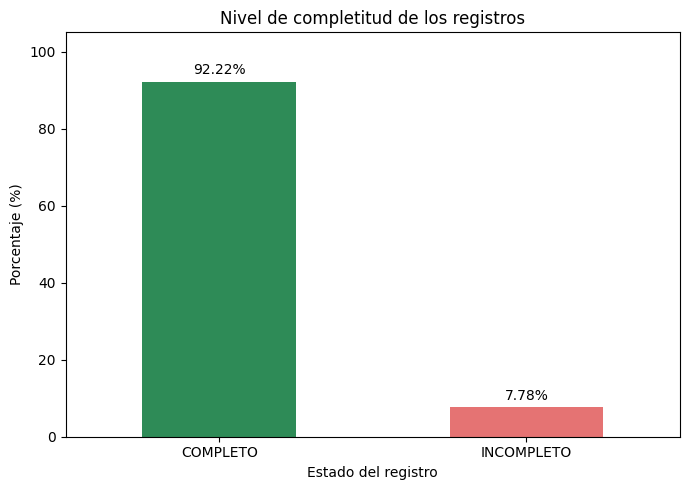

In [97]:
# Crear gráfico de barras
ax = tabla_completitud['PORCENTAJE (%)'].plot(
    kind='bar',
    figsize=(7, 5),
    color=['#2E8B57', '#E57373']
)

# Agregar títulos
plt.title('Nivel de completitud de los registros')
plt.xlabel('Estado del registro')
plt.ylabel('Porcentaje (%)')

# Mostrar porcentajes sobre las barras
for barras in ax.containers:
    ax.bar_label(barras, fmt='%.2f%%', padding=3)

plt.xticks(rotation=0)
plt.ylim(0, 105)
plt.tight_layout()
plt.show()


CUMPLIMIENTO SEGÚN MOTIVO

In [98]:
# Verificar datos faltantes según motivo
tabla_faltantes = df_diagnostico.groupby(
    'MOTIVO', observed=True
)[['CANTIDAD', 'FECHA']].apply(
    lambda datos: datos.isna().sum()
)

tabla_faltantes


,CANTIDAD,FECHA
MOTIVO,,
PINCHADO,9,271
VENCIDO,7,2


In [99]:
# Función para evaluar el cumplimiento
def validar_cumplimiento(fila):

    if fila['MOTIVO'] == 'PINCHADO':
        return 'CUMPLE' if pd.notna(fila['CANTIDAD']) else 'NO CUMPLE'

    elif fila['MOTIVO'] == 'VENCIDO':
        return 'CUMPLE' if (
            pd.notna(fila['CANTIDAD']) and
            pd.notna(fila['FECHA'])
        ) else 'NO CUMPLE'

    return 'NO APLICA'


In [100]:
# Evaluar todos los registros
df_diagnostico['CUMPLIMIENTO SEGÚN MOTIVO'] = (
    df_diagnostico.apply(validar_cumplimiento, axis=1)
)

# Contar los resultados
df_diagnostico['CUMPLIMIENTO SEGÚN MOTIVO'].value_counts()


,count
CUMPLIMIENTO SEGÚN MOTIVO,
CUMPLE,483
NO CUMPLE,18


In [101]:
# Crear tabla de cumplimiento por motivo
tabla_cumplimiento = pd.crosstab(
    df_diagnostico['MOTIVO'],
    df_diagnostico['CUMPLIMIENTO SEGÚN MOTIVO']
)

tabla_cumplimiento


CUMPLIMIENTO SEGÚN MOTIVO,CUMPLE,NO CUMPLE
MOTIVO,,
PINCHADO,262,9
VENCIDO,221,9


In [102]:
# Calcular porcentajes por motivo
tabla_porcentaje = (
    tabla_cumplimiento
    .div(tabla_cumplimiento.sum(axis=1), axis=0)
    * 100
).round(2)

# Mostrar resultados
tabla_porcentaje


CUMPLIMIENTO SEGÚN MOTIVO,CUMPLE,NO CUMPLE
MOTIVO,,
PINCHADO,96.68,3.32
VENCIDO,96.09,3.91


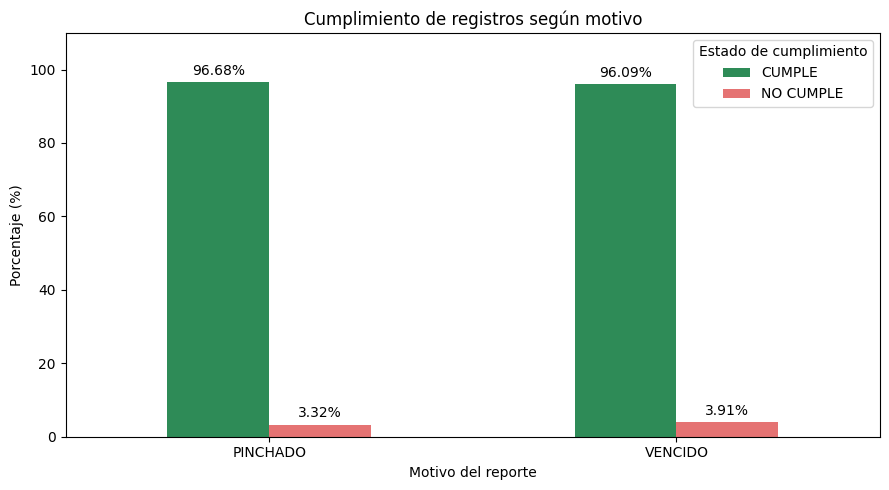

In [103]:
# Crear gráfico de barras agrupadas
ax = tabla_porcentaje.plot(
    kind='bar',
    figsize=(9, 5),
    color=['#2E8B57', '#E57373']
)

# Títulos y ejes
plt.title('Cumplimiento de registros según motivo')
plt.xlabel('Motivo del reporte')
plt.ylabel('Porcentaje (%)')

# Mostrar porcentajes encima de las barras
for barras in ax.containers:
    ax.bar_label(barras, fmt='%.2f%%', padding=3)

# Ajustes del gráfico
plt.xticks(rotation=0)
plt.ylim(0, 110)
plt.legend(title='Estado de cumplimiento')
plt.tight_layout()
plt.show()


COMPORTAMIENTO DE LOS REPORTES

In [104]:
# Obtener año y semana de cada reporte
iso = df_diagnostico['FECHA DE REVISIÓN'].dt.isocalendar()

# Crear las columnas
df_diagnostico['AÑO'] = iso.year
df_diagnostico['SEMANA'] = iso.week

# Visualizar el resultado
display(
    df_diagnostico[
        ['FECHA DE REVISIÓN', 'AÑO', 'SEMANA']
    ].head(10)
)


,FECHA DE REVISIÓN,AÑO,SEMANA
0,2026-03-30,2026,14
1,2026-03-30,2026,14
2,2026-03-30,2026,14
3,2026-03-30,2026,14
4,2026-03-30,2026,14
5,2026-03-30,2026,14
6,2026-03-30,2026,14
7,2026-03-30,2026,14
8,2026-03-30,2026,14
9,2026-03-30,2026,14


In [105]:
# Identificar el período de análisis
print("Primera fecha:",
      df_diagnostico['FECHA DE REVISIÓN'].min())

print("Última fecha:",
      df_diagnostico['FECHA DE REVISIÓN'].max())

print("Semanas diferentes:",
      df_diagnostico[['AÑO', 'SEMANA']].drop_duplicates().dropna().shape[0])


Primera fecha: 2026-03-25 00:00:00
Última fecha: 2026-07-20 00:00:00
Semanas diferentes: 16


In [106]:
# Crear el período semanal
periodo = df_diagnostico['FECHA DE REVISIÓN'].dt.to_period('W-SUN')

# Obtener inicio y fin de semana
df_diagnostico['INICIO SEMANA'] = periodo.dt.start_time
df_diagnostico['FIN SEMANA'] = periodo.dt.end_time.dt.normalize()


In [107]:
# Mostrar las primeras fechas y sus semanas
display(
    df_diagnostico[
        ['FECHA DE REVISIÓN',
         'AÑO',
         'SEMANA',
         'INICIO SEMANA',
         'FIN SEMANA']
    ].head(10)
)


,FECHA DE REVISIÓN,AÑO,SEMANA,INICIO SEMANA,FIN SEMANA
0,2026-03-30,2026,14,2026-03-30,2026-04-05
1,2026-03-30,2026,14,2026-03-30,2026-04-05
2,2026-03-30,2026,14,2026-03-30,2026-04-05
3,2026-03-30,2026,14,2026-03-30,2026-04-05
4,2026-03-30,2026,14,2026-03-30,2026-04-05
5,2026-03-30,2026,14,2026-03-30,2026-04-05
6,2026-03-30,2026,14,2026-03-30,2026-04-05
7,2026-03-30,2026,14,2026-03-30,2026-04-05
8,2026-03-30,2026,14,2026-03-30,2026-04-05
9,2026-03-30,2026,14,2026-03-30,2026-04-05


In [108]:
# Contar registros por semana y sucursal
reportes_semanales = (
    df_diagnostico
    .groupby(
        ['AÑO', 'SEMANA', 'PUNTO DE VENTA'],
        observed=True
    )
    .size()
    .reset_index(name='NÚMERO DE REGISTROS')
)

display(reportes_semanales.head(20))


,AÑO,SEMANA,PUNTO DE VENTA,NÚMERO DE REGISTROS
0,2026,13,SUCURSAL_001,1
1,2026,13,SUCURSAL_002,3
2,2026,14,SUCURSAL_001,11
3,2026,14,SUCURSAL_002,2
4,2026,14,SUCURSAL_003,5
5,2026,14,SUCURSAL_004,8
6,2026,14,SUCURSAL_005,6
7,2026,14,SUCURSAL_007,9
8,2026,15,SUCURSAL_003,4
9,2026,15,SUCURSAL_004,8


In [109]:
# Lista de sucursales observadas en el conjunto de datos.
# Para medir cumplimiento formal, contrastar con un padrón externo de sucursales obligadas.
sucursales = sorted(df_diagnostico['PUNTO DE VENTA'].dropna().astype(str).unique().tolist())
print('Sucursales con algún registro en el período:', len(sucursales))


Sucursales con algún registro en el período: 7


In [110]:
# Crear todas las semanas entre la primera y última fecha
semanas = pd.period_range(
    start=df_diagnostico['FECHA DE REVISIÓN'].min(),
    end=df_diagnostico['FECHA DE REVISIÓN'].max(),
    freq='W-SUN'
)

print("Semanas del período:", len(semanas))


Semanas del período: 18


In [111]:
# Crear todas las combinaciones de semanas y sucursales
esperados = pd.MultiIndex.from_product(
    [semanas, sucursales],
    names=['PERIODO_SEMANA', 'PUNTO DE VENTA']
).to_frame(index=False)

# Mostrar las primeras filas
display(esperados.head(15))


,PERIODO_SEMANA,PUNTO DE VENTA
0,2026-03-23/2026-03-29,SUCURSAL_001
1,2026-03-23/2026-03-29,SUCURSAL_002
2,2026-03-23/2026-03-29,SUCURSAL_003
3,2026-03-23/2026-03-29,SUCURSAL_004
4,2026-03-23/2026-03-29,SUCURSAL_005
5,2026-03-23/2026-03-29,SUCURSAL_006
6,2026-03-23/2026-03-29,SUCURSAL_007
7,2026-03-30/2026-04-05,SUCURSAL_001
8,2026-03-30/2026-04-05,SUCURSAL_002
9,2026-03-30/2026-04-05,SUCURSAL_003


In [112]:
# Crear período semanal de cada registro
df_diagnostico['PERIODO_SEMANA'] = (
    df_diagnostico['FECHA DE REVISIÓN']
    .dt.to_period('W-SUN')
)


In [113]:
# Identificar sucursales con registros por semana
reportados = df_diagnostico[
    ['PERIODO_SEMANA', 'PUNTO DE VENTA']
].dropna().drop_duplicates()

# Crear columna de confirmación
reportados['REPORTÓ'] = 'SI'

display(reportados.head(15))


,PERIODO_SEMANA,PUNTO DE VENTA,REPORTÓ
0,2026-03-30/2026-04-05,SUCURSAL_003,SI
3,2026-03-30/2026-04-05,SUCURSAL_001,SI
14,2026-03-23/2026-03-29,SUCURSAL_001,SI
15,2026-03-23/2026-03-29,SUCURSAL_002,SI
18,2026-03-30/2026-04-05,SUCURSAL_002,SI
20,2026-03-30/2026-04-05,SUCURSAL_005,SI
26,2026-03-30/2026-04-05,SUCURSAL_007,SI
39,2026-03-30/2026-04-05,SUCURSAL_004,SI
47,2026-04-06/2026-04-12,SUCURSAL_003,SI
51,2026-04-06/2026-04-12,SUCURSAL_006,SI


In [114]:
# Comparar lo esperado con lo reportado
control_semanal = esperados.merge(
    reportados,
    on=['PERIODO_SEMANA', 'PUNTO DE VENTA'],
    how='left'
)


In [115]:
# Identificar las combinaciones sin registros
control_semanal['REPORTÓ'] = (
    control_semanal['REPORTÓ'].fillna('NO')
)

# Mostrar los primeros resultados
display(control_semanal.head(15))


,PERIODO_SEMANA,PUNTO DE VENTA,REPORTÓ
0,2026-03-23/2026-03-29,SUCURSAL_001,SI
1,2026-03-23/2026-03-29,SUCURSAL_002,SI
2,2026-03-23/2026-03-29,SUCURSAL_003,NO
3,2026-03-23/2026-03-29,SUCURSAL_004,NO
4,2026-03-23/2026-03-29,SUCURSAL_005,NO
5,2026-03-23/2026-03-29,SUCURSAL_006,NO
6,2026-03-23/2026-03-29,SUCURSAL_007,NO
7,2026-03-30/2026-04-05,SUCURSAL_001,SI
8,2026-03-30/2026-04-05,SUCURSAL_002,SI
9,2026-03-30/2026-04-05,SUCURSAL_003,SI


In [116]:
# Resumen de cobertura semanal
resumen_semanal = control_semanal.groupby(
    'PERIODO_SEMANA'
).agg(
    SUCURSALES_ESPERADAS=('PUNTO DE VENTA', 'size'),
    SUCURSALES_CON_REGISTROS=('REPORTÓ', lambda x: (x == 'SI').sum())
).reset_index()

display(resumen_semanal)


,PERIODO_SEMANA,SUCURSALES_ESPERADAS,SUCURSALES_CON_REGISTROS
0,2026-03-23/2026-03-29,7,2
1,2026-03-30/2026-04-05,7,6
2,2026-04-06/2026-04-12,7,3
3,2026-04-13/2026-04-19,7,5
4,2026-04-20/2026-04-26,7,7
5,2026-04-27/2026-05-03,7,4
6,2026-05-04/2026-05-10,7,3
7,2026-05-11/2026-05-17,7,2
8,2026-05-18/2026-05-24,7,0
9,2026-05-25/2026-05-31,7,3


In [117]:
# Calcular porcentaje de cobertura
resumen_semanal['COBERTURA (%)'] = (
    resumen_semanal['SUCURSALES_CON_REGISTROS']
    / resumen_semanal['SUCURSALES_ESPERADAS'] * 100
).round(2)

display(resumen_semanal)


,PERIODO_SEMANA,SUCURSALES_ESPERADAS,SUCURSALES_CON_REGISTROS,COBERTURA (%)
0,2026-03-23/2026-03-29,7,2,28.57
1,2026-03-30/2026-04-05,7,6,85.71
2,2026-04-06/2026-04-12,7,3,42.86
3,2026-04-13/2026-04-19,7,5,71.43
4,2026-04-20/2026-04-26,7,7,100.00
5,2026-04-27/2026-05-03,7,4,57.14
6,2026-05-04/2026-05-10,7,3,42.86
7,2026-05-11/2026-05-17,7,2,28.57
8,2026-05-18/2026-05-24,7,0,0.00
9,2026-05-25/2026-05-31,7,3,42.86


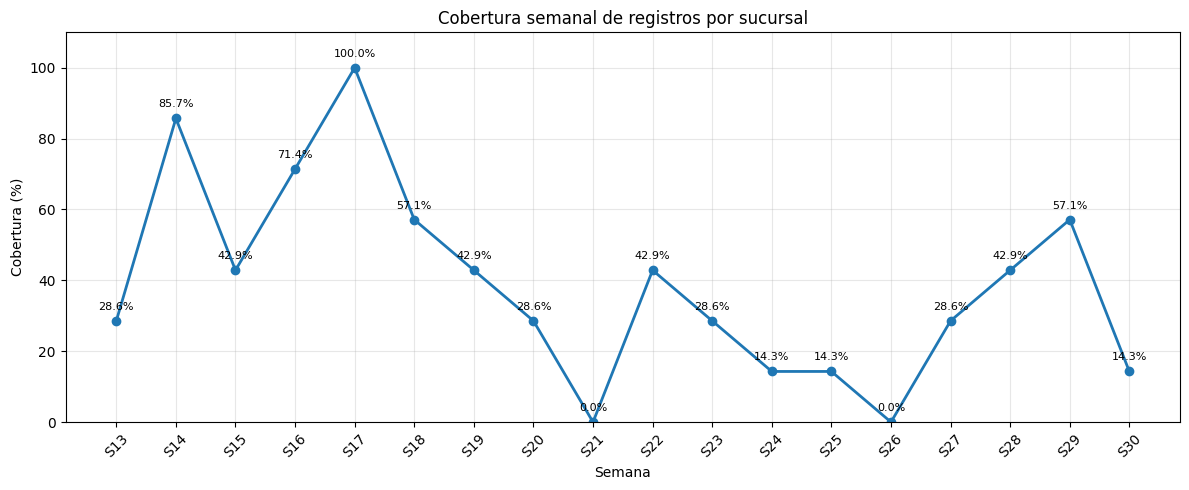

In [118]:
# Crear etiquetas de las semanas
resumen_semanal['SEMANA'] = (
    'S' +
    resumen_semanal['PERIODO_SEMANA']
    .dt.start_time.dt.isocalendar().week.astype(str)
)

# Crear gráfico de líneas
plt.figure(figsize=(12, 5))

plt.plot(
    resumen_semanal['SEMANA'],
    resumen_semanal['COBERTURA (%)'],
    marker='o',
    linewidth=2
)

plt.title('Cobertura semanal de registros por sucursal')
plt.xlabel('Semana')
plt.ylabel('Cobertura (%)')
plt.ylim(0, 110)
plt.grid(True, alpha=0.3)

# Mostrar porcentajes
for x, y in zip(
    resumen_semanal['SEMANA'],
    resumen_semanal['COBERTURA (%)']
):
    plt.annotate(
        f'{y:.1f}%',
        (x, y),
        textcoords='offset points',
        xytext=(0, 8),
        ha='center',
        fontsize=8
    )

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [119]:
# Calcular promedio de cobertura semanal
promedio_cobertura = resumen_semanal['COBERTURA (%)'].mean()

print(f"Cobertura semanal promedio: {promedio_cobertura:.2f}%")


Cobertura semanal promedio: 38.89%


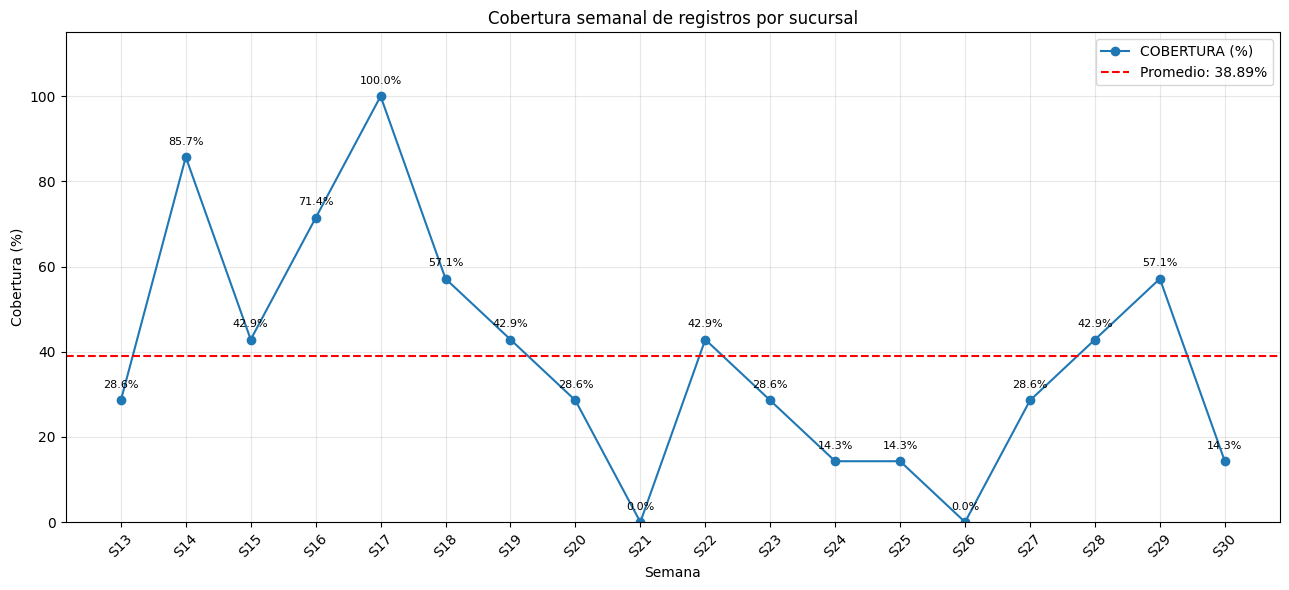

In [120]:
# Crear gráfico de cobertura semanal
ax = resumen_semanal.plot(
    x='SEMANA',
    y='COBERTURA (%)',
    kind='line',
    marker='o',
    figsize=(13, 6),
    legend=False
)

# Agregar línea del promedio
plt.axhline(
    y=promedio_cobertura,
    color='red',
    linestyle='--',
    label=f'Promedio: {promedio_cobertura:.2f}%'
)

# Mostrar porcentajes sobre cada punto
for i, valor in enumerate(resumen_semanal['COBERTURA (%)']):
    ax.annotate(
        f'{valor:.1f}%',
        (i, valor),
        xytext=(0, 9),
        textcoords='offset points',
        ha='center',
        fontsize=8
    )

# Configuración
plt.title('Cobertura semanal de registros por sucursal')
plt.xlabel('Semana')
plt.ylabel('Cobertura (%)')

plt.xticks(
    range(len(resumen_semanal)),
    resumen_semanal['SEMANA'],
    rotation=45
)

plt.ylim(0, 115)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()



REGISTROS DUPLICADOS EXACTOS

In [121]:
# Contar registros duplicados exactos
duplicados = df_diagnostico[
    [
        'MOTIVO',
        'FECHA DE REVISIÓN',
        'PUNTO DE VENTA',
        'PRODUCTO',
        'CANTIDAD',
        'FECHA',
        'NOMBRE ESTÁNDAR',
        'CÓDIGO DE BARRA',
        'CÓDIGO DE PRODUCTO'
    ]
].duplicated().sum()

print("Registros duplicados exactos:", duplicados)


Registros duplicados exactos: 18


In [122]:
# Revisar cuántas filas participan en grupos duplicados, sin mostrar datos privados
columnas_duplicados = ['MOTIVO', 'FECHA DE REVISIÓN', 'PUNTO DE VENTA', 'PRODUCTO', 'CANTIDAD', 'FECHA', 'NOMBRE ESTÁNDAR', 'CÓDIGO DE BARRA', 'CÓDIGO DE PRODUCTO']
registros_duplicados = df_diagnostico[df_diagnostico[columnas_duplicados].duplicated(keep=False)]
print('Filas en grupos duplicados:', len(registros_duplicados))


Filas en grupos duplicados: 32


In [123]:
# Recuento de duplicados adicionales
print('Duplicados exactos adicionales:', duplicados)


Duplicados exactos adicionales: 18


VALORES FALTANTE POR VARIABLE

In [124]:
# Contar valores faltantes por columna obligatoria
faltantes = (
    df_diagnostico[columnas_obligatorias]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

display(faltantes)


,0
CANTIDAD,16
NOMBRE ESTÁNDAR,15
PUNTO DE VENTA,12
CÓDIGO DE PRODUCTO,8
CÓDIGO DE BARRA,6
FECHA DE REVISIÓN,2
MOTIVO,0


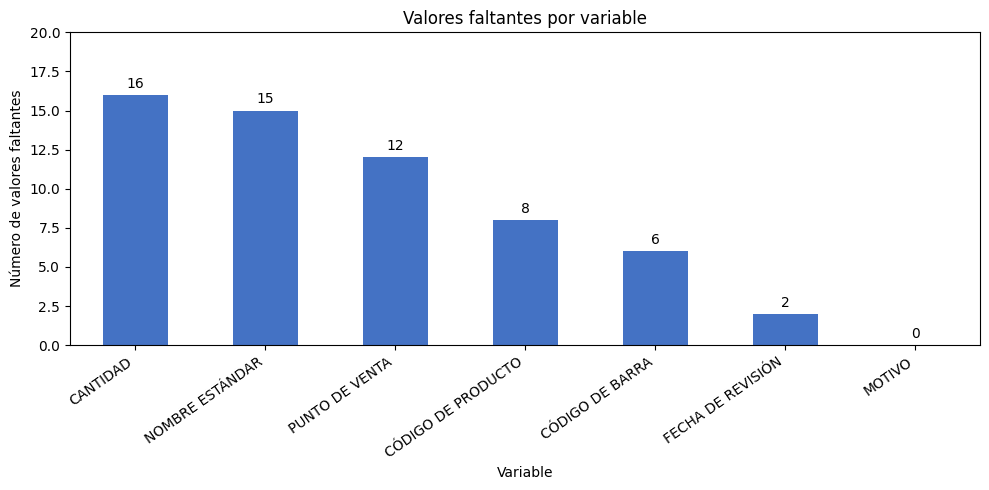

In [125]:
# Crear gráfico de valores faltantes
ax = faltantes.plot(
    kind='bar',
    figsize=(10, 5),
    color='#4472C4'
)

plt.title('Valores faltantes por variable')
plt.xlabel('Variable')
plt.ylabel('Número de valores faltantes')

# Mostrar cantidades encima de las barras
for barras in ax.containers:
    ax.bar_label(barras, fmt='%d', padding=3)

plt.xticks(rotation=35, ha='right')
plt.ylim(0, 20)
plt.tight_layout()
plt.show()
